# Phase 3: Sensor Network Topology & Road Adjacency Construction
### Modeling the Urban Road Network as a Spatial Graph $\mathcal{G} = (\mathcal{V}, \mathcal{E}, W)$

This notebook covers:
1. Downloading and loading physical sensor topology files (`distances_la_2012.csv`, sensor IDs, GPS coordinates).
2. Constructing the pairwise distance matrix across 207 sensors.
3. Calculating the thresholded Gaussian distance kernel adjacency matrix $A_{ij} = \exp(-(d_{ij}/\sigma)^2)$ with self-loops.
4. Geospatial visualization of sensor locations and road segment connectivity.


## Section 1: Environment Setup, Dependencies & System Configuration
We configure the runtime environment, set plotting styles, verify GPU hardware acceleration, and import fundamental scientific computing libraries (`numpy`, `pandas`, `matplotlib`).


In [4]:
#Day01_Traffic_Exploration.ipynb
# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

print("Setup complete ")


Setup complete 


## Section 6: Road Network Topology & Graph Adjacency Matrix Construction
Urban traffic flow is constrained by the underlying physical road network topology.
We model the sensor network as a directed, weighted graph $\mathcal{G} = (\mathcal{V}, \mathcal{E}, W)$, where:
- Nodes $v_i \in \mathcal{V}$ represent the 207 traffic sensors.
- Edges $(v_i, v_j) \in \mathcal{E}$ represent physical road connections between sensors.
- Edge weights $W_{ij}$ are derived via a thresholded Gaussian distance kernel:
$$W_{ij} = \begin{cases} \exp\left(-\frac{\text{dist}(v_i, v_j)^2}{\sigma^2}\right), & \text{if } \text{dist}(v_i, v_j) \le \kappa \\ 0, & \text{otherwise} \end{cases}$$

### 6.1 Download & Ingest Sensor Topology Files


In [ ]:
import urllib.request

base = "https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/"
files = ["distances_la_2012.csv", "graph_sensor_ids.txt", "graph_sensor_locations.csv"]

for fname in files:
    urllib.request.urlretrieve(base + fname, fname)
    print(f"downloaded {fname}")


downloaded distances_la_2012.csv
downloaded graph_sensor_ids.txt
downloaded graph_sensor_locations.csv


### 6.2 Compute Distance Matrix & Thresholded Adjacency Matrix $A$


In [ ]:
import numpy as np
import pandas as pd

with open('graph_sensor_ids.txt') as f:
    sensor_ids = f.read().strip().split(',')
num_sensors = len(sensor_ids)
id_to_idx = {sid: i for i, sid in enumerate(sensor_ids)}

dist_df = pd.read_csv('distances_la_2012.csv', dtype={'from': str, 'to': str})
print(dist_df.columns.tolist())  # sanity check: should be ['from', 'to', 'cost']

dist_mx = np.full((num_sensors, num_sensors), np.inf)

froms = dist_df['from'].values
tos = dist_df['to'].values
costs = dist_df['cost'].values

for f, t, c in zip(froms, tos, costs):
    if f in id_to_idx and t in id_to_idx:
        dist_mx[id_to_idx[f], id_to_idx[t]] = c

distances = dist_mx[~np.isinf(dist_mx)].flatten()
std = distances.std()
adj_mx = np.exp(-np.square(dist_mx / std))
adj_mx[adj_mx < 0.1] = 0
np.fill_diagonal(adj_mx, 1.0)

print(adj_mx.shape)
print((adj_mx > 0).sum(), "edges (incl. self-loops)")


['from', 'to', 'cost']
(207, 207)
1722 edges (incl. self-loops)


## Section 7: Geospatial Road Network Sensor Layout Visualization
Visualizing the physical coordinates of the 207 sensors across the Los Angeles highway network, overlaid with connectivity edges representing road segments.


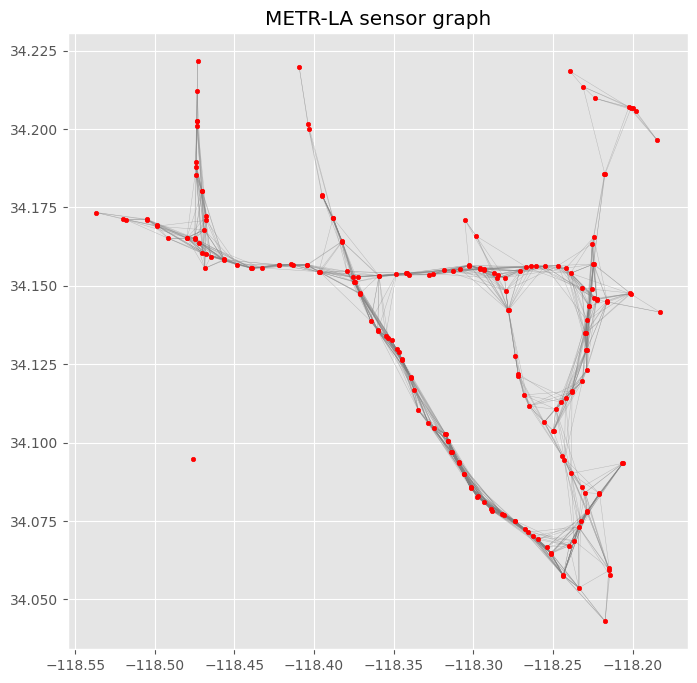

In [ ]:
import matplotlib.pyplot as plt

loc_df = pd.read_csv('graph_sensor_locations.csv')
loc_df['sensor_id'] = loc_df['sensor_id'].astype(str)
loc_df = loc_df.set_index('sensor_id').loc[sensor_ids].reset_index()

plt.figure(figsize=(8,8))
for i in range(num_sensors):
    for j in range(num_sensors):
        if adj_mx[i,j] > 0 and i != j:
            plt.plot([loc_df.longitude[i], loc_df.longitude[j]],
                     [loc_df.latitude[i], loc_df.latitude[j]],
                     'gray', linewidth=0.3, alpha=0.5)
plt.scatter(loc_df.longitude, loc_df.latitude, s=10, c='red', zorder=5)
plt.title("METR-LA sensor graph")
plt.show()
